# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm

Dataset: BloodMNIST (8 types of blood cells, MedMNIST v2)

Plan: HOG features -> baseline SVM (all features) -> Genetic Algorithm picks a smaller set of HOG features -> SVM on the selected features -> compare on the test set.

Run the cells from top to bottom. The GA part takes several minutes, and the test set is only used in the final evaluation cell.

In [4]:
!pip install -q medmnist

In [5]:
import time, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             cohen_kappa_score, matthews_corrcoef, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

MAX_TRAIN_PER_CLASS = 200
MAX_VAL_PER_CLASS = 100
MAX_TEST_PER_CLASS = 200
IMG = 128
C_GRID = (1, 10, 100)

PENALTY = 0.05
GENERATIONS = 15
ELITE = 2
CROSS_PROB = 0.9
TOURNAMENT = 3
GA_SETTINGS = {
    "GA-1 (pop 20, mut 0.005)": {"pop": 20, "mut": 0.005},
    "GA-2 (pop 40, mut 0.005)": {"pop": 40, "mut": 0.005},
    "GA-3 (pop 20, mut 0.02)": {"pop": 20, "mut": 0.02},
}

## Tasks 1-2: Dataset and preprocessing

In [6]:
from medmnist import BloodMNIST, INFO

class_names = [INFO["bloodmnist"]["label"][str(i)] for i in range(len(INFO["bloodmnist"]["label"]))]
NUM_CLASSES = len(class_names)

def load_split(split):
    last_error = None
    for size in (128, 64, None):
        try:
            ds = BloodMNIST(split=split, download=True, size=size) if size else BloodMNIST(split=split, download=True)
            if size != 128:
                print("note: using image size", size, "and resizing to 128")
            return ds.imgs, ds.labels.ravel()
        except Exception as e:
            last_error = e
    raise last_error

def subsample(imgs, labels, cap, seed):
    rng = np.random.default_rng(seed)
    keep = []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        if len(idx) > cap:
            idx = rng.choice(idx, cap, replace=False)
        keep.extend(idx.tolist())
    keep = np.array(sorted(keep))
    return imgs[keep], labels[keep]

def preprocess(imgs):
    out = np.empty((len(imgs), IMG, IMG), np.uint8)
    for i, im in enumerate(imgs):
        g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY) if im.ndim == 3 else im
        interp = cv2.INTER_AREA if g.shape[0] > IMG else cv2.INTER_LINEAR
        out[i] = cv2.resize(g, (IMG, IMG), interpolation=interp)
    return out

data = {}
for split, cap in (("train", MAX_TRAIN_PER_CLASS), ("val", MAX_VAL_PER_CLASS), ("test", MAX_TEST_PER_CLASS)):
    imgs, labels = load_split(split)
    imgs, labels = subsample(imgs, labels, cap, SEED)
    data[split] = (preprocess(imgs), labels)

img_tr, ytr = data["train"]
img_va, yva = data["val"]
img_te, yte = data["test"]

counts = pd.DataFrame({
    "train": np.bincount(ytr, minlength=NUM_CLASSES),
    "val": np.bincount(yva, minlength=NUM_CLASSES),
    "test": np.bincount(yte, minlength=NUM_CLASSES),
}, index=class_names)
counts.loc["total"] = counts.sum()
print(counts)

100%|██████████| 569M/569M [02:51<00:00, 3.31MB/s]


                                                    train  val  test
basophil                                              200  100   200
eosinophil                                            200  100   200
erythroblast                                          200  100   200
immature granulocytes(myelocytes, metamyelocyte...    200  100   200
lymphocyte                                            200  100   200
monocyte                                              200  100   200
neutrophil                                            200  100   200
platelet                                              200  100   200
total                                                1600  800  1600


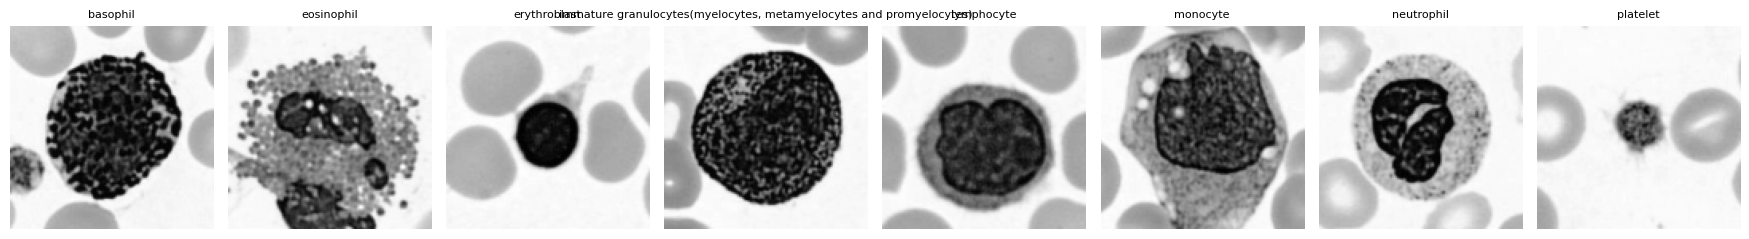

In [7]:
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(2.2 * NUM_CLASSES, 2.6))
for c in range(NUM_CLASSES):
    axes[c].imshow(img_tr[ytr == c][0], cmap="gray")
    axes[c].set_title(class_names[c], fontsize=8)
    axes[c].axis("off")
plt.tight_layout()
plt.show()

## Tasks 3-4: HOG feature extraction

In [8]:
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys")

def extract(images):
    return np.array([hog(im, **HOG_PARAMS) for im in images], dtype=np.float32)

t0 = time.time()
Xtr, Xva, Xte = extract(img_tr), extract(img_va), extract(img_te)
hog_time = time.time() - t0
D = Xtr.shape[1]
print("HOG features per image:", D)
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)
print("HOG extraction time: %.1f s" % hog_time)

HOG features per image: 8100
train (1600, 8100) | val (800, 8100) | test (1600, 8100)
HOG extraction time: 27.2 s


In [9]:
table1 = pd.DataFrame([
    ["Medical dataset", "BloodMNIST", "BloodMNIST"],
    ["Image resolution", "%d x %d" % (IMG, IMG), "%d x %d" % (IMG, IMG)],
    ["HOG orientations", 9, 9],
    ["Pixels per cell", "8 x 8", "8 x 8"],
    ["Cells per block", "2 x 2", "2 x 2"],
    ["Block normalization", "L2-Hys", "L2-Hys"],
    ["Number of HOG features", D, "selected by GA"],
    ["Feature selection", "None", "Genetic Algorithm"],
    ["Classifier", "SVM", "SVM"],
    ["SVM kernel", "RBF", "RBF"],
    ["Hyperparameter tuning", "Validation set (C in %s)" % (C_GRID,), "Validation set (C in %s)" % (C_GRID,)],
    ["Data split", "Fixed: %d / %d / %d (train/val/test)" % (len(ytr), len(yva), len(yte)), "Same split"],
    ["Random seed", SEED, SEED],
], columns=["Parameter", "Baseline: HOG + SVM", "Proposed: GA-HOG + SVM"])
table1

,Parameter,Baseline: HOG + SVM,Proposed: GA-HOG + SVM
0,Medical dataset,BloodMNIST,BloodMNIST
1,Image resolution,128 x 128,128 x 128
2,HOG orientations,9,9
3,Pixels per cell,8 x 8,8 x 8
4,Cells per block,2 x 2,2 x 2
5,Block normalization,L2-Hys,L2-Hys
6,Number of HOG features,8100,selected by GA
7,Feature selection,None,Genetic Algorithm
8,Classifier,SVM,SVM
9,SVM kernel,RBF,RBF


## Tasks 3 and 7: Baseline HOG + SVM (all features)

In [10]:
def metrics_all(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    tp = np.diag(cm)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    tn = cm.sum() - tp - fp - fn
    specificity = np.mean(tn / np.maximum(tn + fp, 1))
    return {
        "Accuracy (%)": 100 * accuracy_score(y_true, y_pred),
        "Precision (Macro, %)": 100 * precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (Macro, %)": 100 * recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro-F1 (%)": 100 * f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Weighted-F1 (%)": 100 * f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y_true, y_pred),
        "Specificity (Macro, %)": 100 * specificity,
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
        "Matthews correlation coefficient": matthews_corrcoef(y_true, y_pred),
    }

def rbf_kernels(A, others):
    gamma = 1.0 / (A.shape[1] * A.var())
    na = (A * A).sum(1)
    Ktt = np.exp(-gamma * np.maximum(na[:, None] + na[None, :] - 2 * (A @ A.T), 0))
    outs = []
    for B in others:
        nb = (B * B).sum(1)
        outs.append(np.exp(-gamma * np.maximum(nb[:, None] + na[None, :] - 2 * (B @ A.T), 0)))
    return Ktt, outs

def val_macro_f1(cols, C):
    A, B = Xtr[:, cols], Xva[:, cols]
    Ktt, (Kvt,) = rbf_kernels(A, [B])
    pred = SVC(kernel="precomputed", C=C).fit(Ktt, ytr).predict(Kvt)
    return f1_score(yva, pred, average="macro")

def tune_C(cols):
    A, B = Xtr[:, cols], Xva[:, cols]
    Ktt, (Kvt,) = rbf_kernels(A, [B])
    scores = {}
    for C in C_GRID:
        pred = SVC(kernel="precomputed", C=C).fit(Ktt, ytr).predict(Kvt)
        scores[C] = f1_score(yva, pred, average="macro")
    best = max(scores, key=scores.get)
    return best, scores

In [11]:
rng = np.random.default_rng(0)
test_cols = np.where(rng.random(D) < 0.5)[0]
fast = SVC(kernel="precomputed", C=10)
Ktt, (Kvt,) = rbf_kernels(Xtr[:, test_cols], [Xva[:, test_cols]])
pred_fast = fast.fit(Ktt, ytr).predict(Kvt)
pred_std = SVC(kernel="rbf", C=10, gamma="scale").fit(Xtr[:, test_cols], ytr).predict(Xva[:, test_cols])
print("Fast GA fitness check - predictions identical to standard SVC:", np.mean(pred_fast == pred_std) * 100, "%")

Fast GA fitness check - predictions identical to standard SVC: 100.0 %


In [12]:
all_cols = np.arange(D)
BASE_C, base_scores = tune_C(all_cols)
print("Baseline validation macro-F1 for each C:", {c: round(s, 4) for c, s in base_scores.items()}, "-> C =", BASE_C)

baseline = SVC(kernel="rbf", C=BASE_C, gamma="scale")
t0 = time.time()
baseline.fit(Xtr, ytr)
base_train_time = time.time() - t0
base_val_f1 = f1_score(yva, baseline.predict(Xva), average="macro")
print("Baseline: %d features | validation macro-F1 %.4f | training time %.1f s" % (D, base_val_f1, base_train_time))

Baseline validation macro-F1 for each C: {1: 0.6244, 10: 0.6604, 100: 0.6604} -> C = 10
Baseline: 8100 features | validation macro-F1 0.6604 | training time 15.6 s


## Tasks 5-6: Genetic Algorithm feature selection

Each individual is a 0/1 vector with one gene per HOG feature (1 = keep the feature).

fitness = validation macro-F1 - PENALTY x (selected features / all features)

In [13]:
def fitness_of(ind, cache):
    key = np.packbits(ind).tobytes()
    if key not in cache:
        cols = np.where(ind)[0]
        f1 = val_macro_f1(cols, BASE_C)
        cache[key] = (f1 - PENALTY * len(cols) / D, f1)
    return cache[key]

def tournament(fits, rng):
    cand = rng.integers(0, len(fits), TOURNAMENT)
    return cand[np.argmax(fits[cand])]

def run_ga(pop_size, mut_prob, seed):
    rng = np.random.default_rng(seed)
    cache = {}
    pop = rng.random((pop_size, D)) < 0.5
    hist = {"best_fitness": [], "mean_fitness": [], "best_f1": [], "best_features": []}
    t0 = time.time()
    for gen in range(GENERATIONS):
        res = [fitness_of(ind, cache) for ind in pop]
        fits = np.array([r[0] for r in res])
        f1s = np.array([r[1] for r in res])
        order = np.argsort(-fits)
        hist["best_fitness"].append(fits[order[0]])
        hist["mean_fitness"].append(fits.mean())
        hist["best_f1"].append(f1s[order[0]])
        hist["best_features"].append(int(pop[order[0]].sum()))
        if gen == GENERATIONS - 1:
            break
        new_pop = [pop[order[i]].copy() for i in range(ELITE)]
        while len(new_pop) < pop_size:
            p1, p2 = pop[tournament(fits, rng)], pop[tournament(fits, rng)]
            if rng.random() < CROSS_PROB:
                swap = rng.random(D) < 0.5
                c1, c2 = np.where(swap, p1, p2), np.where(swap, p2, p1)
            else:
                c1, c2 = p1.copy(), p2.copy()
            for c in (c1, c2):
                c ^= rng.random(D) < mut_prob
                if not c.any():
                    c[rng.integers(D)] = True
                new_pop.append(c)
        pop = np.array(new_pop[:pop_size])
    return {"best": pop[order[0]].copy(), "hist": hist, "time": time.time() - t0}

In [14]:
ga_runs = {}
for name, cfg in GA_SETTINGS.items():
    ga_runs[name] = run_ga(cfg["pop"], cfg["mut"], SEED)
    h = ga_runs[name]["hist"]
    print("%s done in %.0f s | best fitness %.4f | val macro-F1 %.4f | features %d" % (
        name, ga_runs[name]["time"], h["best_fitness"][-1], h["best_f1"][-1], h["best_features"][-1]))

GA-1 (pop 20, mut 0.005) done in 113 s | best fitness 0.6683 | val macro-F1 0.6933 | features 4040
GA-2 (pop 40, mut 0.005) done in 238 s | best fitness 0.6894 | val macro-F1 0.7145 | features 4075
GA-3 (pop 20, mut 0.02) done in 109 s | best fitness 0.6783 | val macro-F1 0.7032 | features 4022


In [15]:
rows = []
for name, r in ga_runs.items():
    h = r["hist"]
    rows.append({
        "GA setting": name,
        "Population": GA_SETTINGS[name]["pop"], "Mutation": GA_SETTINGS[name]["mut"],
        "Best fitness": round(h["best_fitness"][-1], 4),
        "Validation macro-F1": round(h["best_f1"][-1], 4),
        "Selected features": h["best_features"][-1],
        "Features removed (%)": round(100 * (1 - h["best_features"][-1] / D), 1),
        "GA time (s)": round(r["time"], 1),
    })
ga_table = pd.DataFrame(rows)
ga_table.loc[len(ga_table)] = ["Baseline (all features)", "-", "-", round(base_val_f1, 4), round(base_val_f1, 4), D, 0.0, 0.0]
ga_table

,GA setting,Population,Mutation,Best fitness,Validation macro-F1,Selected features,Features removed (%),GA time (s)
0,"GA-1 (pop 20, mut 0.005)",20,0.005,0.6683,0.6933,4040,50.1,113.0
1,"GA-2 (pop 40, mut 0.005)",40,0.005,0.6894,0.7145,4075,49.7,238.0
2,"GA-3 (pop 20, mut 0.02)",20,0.02,0.6783,0.7032,4022,50.3,109.0
3,Baseline (all features),-,-,0.6604,0.6604,8100,0.0,0.0


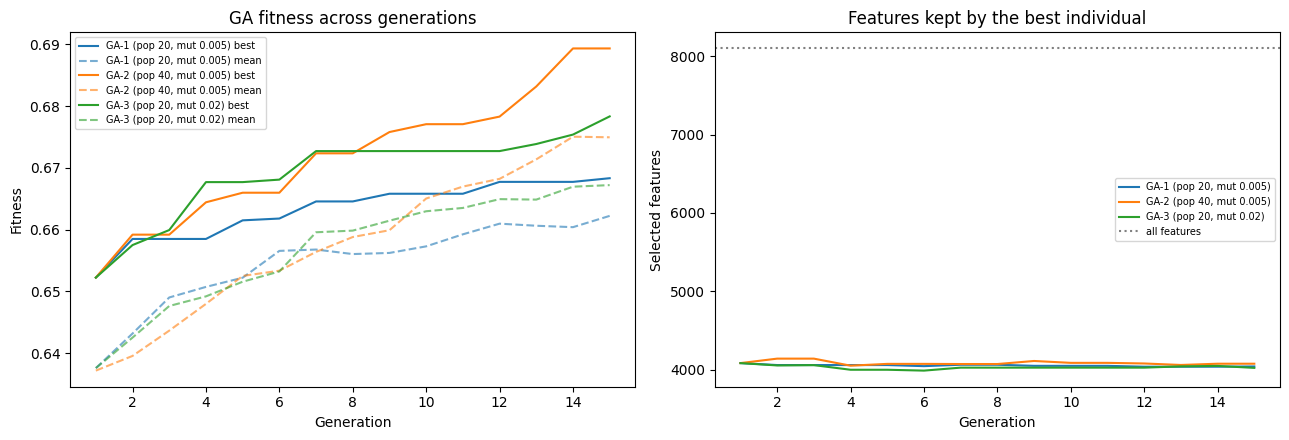

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r in ga_runs.items():
    gens = np.arange(1, GENERATIONS + 1)
    line, = axes[0].plot(gens, r["hist"]["best_fitness"], label=name + " best")
    axes[0].plot(gens, r["hist"]["mean_fitness"], "--", color=line.get_color(), alpha=0.6, label=name + " mean")
    axes[1].plot(gens, r["hist"]["best_features"], label=name)
axes[0].set_xlabel("Generation"); axes[0].set_ylabel("Fitness"); axes[0].set_title("GA fitness across generations")
axes[0].legend(fontsize=7)
axes[1].axhline(D, color="gray", linestyle=":", label="all features")
axes[1].set_xlabel("Generation"); axes[1].set_ylabel("Selected features"); axes[1].set_title("Features kept by the best individual")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Model selection (validation set only)

The GA setting with the best validation fitness is chosen. Its SVM parameter C is tuned on the validation set and the final GA-HOG + SVM model is trained.

In [17]:
best_name = max(ga_runs, key=lambda n: ga_runs[n]["hist"]["best_fitness"][-1])
sel_mask = ga_runs[best_name]["best"]
sel_cols = np.where(sel_mask)[0]
ga_search_time = ga_runs[best_name]["time"]
print("Selected GA setting:", best_name, "| features kept:", len(sel_cols), "of", D)

GA_C, ga_scores = tune_C(sel_cols)
print("GA-HOG validation macro-F1 for each C:", {c: round(s, 4) for c, s in ga_scores.items()}, "-> C =", GA_C)

ga_model = SVC(kernel="rbf", C=GA_C, gamma="scale")
t0 = time.time()
ga_model.fit(Xtr[:, sel_cols], ytr)
ga_train_time = time.time() - t0
print("GA-HOG SVM training time: %.1f s" % ga_train_time)

Selected GA setting: GA-2 (pop 40, mut 0.005) | features kept: 4075 of 8100
GA-HOG validation macro-F1 for each C: {1: 0.6448, 10: 0.7145, 100: 0.7145} -> C = 10
GA-HOG SVM training time: 6.2 s


## Task 8: Final evaluation on the test set (only now)

In [18]:
t0 = time.time()
pred_base = baseline.predict(Xte)
base_infer = (time.time() - t0) / len(yte) * 1000

t0 = time.time()
pred_ga = ga_model.predict(Xte[:, sel_cols])
ga_infer = (time.time() - t0) / len(yte) * 1000

m_base, m_ga = metrics_all(yte, pred_base), metrics_all(yte, pred_ga)
table2 = pd.DataFrame({
    "Metric": list(m_base.keys()),
    "HOG + SVM (Baseline)": [round(v, 2) if "kappa" not in k and "Matthews" not in k else round(v, 4) for k, v in m_base.items()],
    "GA-HOG + SVM (Proposed)": [round(v, 2) if "kappa" not in k and "Matthews" not in k else round(v, 4) for k, v in m_ga.items()],
})
table2["Improvement"] = [round(m_ga[k] - m_base[k], 2) if "kappa" not in k and "Matthews" not in k else round(m_ga[k] - m_base[k], 4) for k in m_base]
table2

,Metric,HOG + SVM (Baseline),GA-HOG + SVM (Proposed),Improvement
0,Accuracy (%),66.6900,66.6900,0.0000
1,"Precision (Macro, %)",67.1400,66.9500,-0.1900
2,"Recall (Macro, %)",66.6900,66.6900,0.0000
3,Macro-F1 (%),66.6600,66.6500,-0.0200
4,Weighted-F1 (%),66.6600,66.6500,-0.0200
5,Balanced accuracy (%),66.6900,66.6900,0.0000
6,"Specificity (Macro, %)",95.2400,95.2400,0.0000
7,Cohen's kappa,0.6193,0.6193,0.0000
8,Matthews correlation coefficient,0.6199,0.6197,-0.0002


In [19]:
table3 = pd.DataFrame([
    ["Number of HOG features", D, len(sel_cols)],
    ["Feature reduction (%)", 0.0, round(100 * (1 - len(sel_cols) / D), 1)],
    ["HOG extraction time (s, all splits)", round(hog_time, 1), round(hog_time, 1)],
    ["GA search time (s)", 0.0, round(ga_search_time, 1)],
    ["SVM training time (s)", round(base_train_time, 1), round(ga_train_time, 1)],
    ["Inference time (ms per image)", round(base_infer, 3), round(ga_infer, 3)],
    ["Total pipeline time (s)", round(hog_time + base_train_time, 1), round(hog_time + ga_search_time + ga_train_time, 1)],
    ["Validation macro-F1", round(base_val_f1, 4), round(ga_scores[GA_C], 4)],
], columns=["Item", "HOG + SVM (Baseline)", "GA-HOG + SVM (Proposed)"])
table3

,Item,HOG + SVM (Baseline),GA-HOG + SVM (Proposed)
0,Number of HOG features,8100.0000,4075.0000
1,Feature reduction (%),0.0000,49.7000
2,"HOG extraction time (s, all splits)",27.2000,27.2000
3,GA search time (s),0.0000,238.0000
4,SVM training time (s),15.6000,6.2000
5,Inference time (ms per image),12.1180,7.2270
6,Total pipeline time (s),42.8000,271.4000
7,Validation macro-F1,0.6604,0.7145


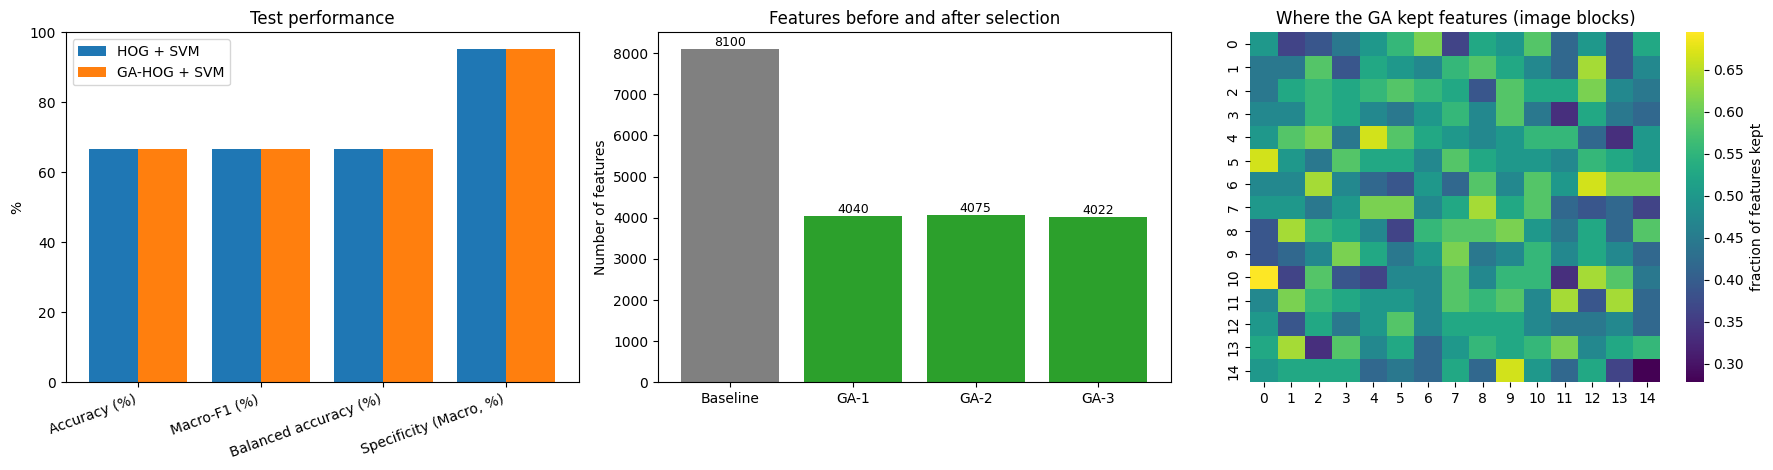

In [20]:
table1.to_csv("table1_configuration.csv", index=False)
table2.to_csv("table2_main_comparison.csv", index=False)
table3.to_csv("table3_computational_cost.csv", index=False)
ga_table.to_csv("table_ga_settings.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

plot_metrics = ["Accuracy (%)", "Macro-F1 (%)", "Balanced accuracy (%)", "Specificity (Macro, %)"]
x = np.arange(len(plot_metrics))
axes[0].bar(x - 0.2, [m_base[k] for k in plot_metrics], 0.4, label="HOG + SVM")
axes[0].bar(x + 0.2, [m_ga[k] for k in plot_metrics], 0.4, label="GA-HOG + SVM")
axes[0].set_xticks(x); axes[0].set_xticklabels(plot_metrics, rotation=20, ha="right")
axes[0].set_ylabel("%"); axes[0].set_title("Test performance"); axes[0].legend()

counts_plot = [D] + [r["hist"]["best_features"][-1] for r in ga_runs.values()]
labels_plot = ["Baseline"] + [n.split(" ")[0] for n in ga_runs]
axes[1].bar(labels_plot, counts_plot, color=["gray"] + ["tab:green"] * len(ga_runs))
for i, v in enumerate(counts_plot):
    axes[1].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
axes[1].set_ylabel("Number of features"); axes[1].set_title("Features before and after selection")

blocks = int(np.sqrt(D / (4 * HOG_PARAMS["orientations"])))
heat = sel_mask.reshape(blocks, blocks, 2, 2, HOG_PARAMS["orientations"]).mean(axis=(2, 3, 4))
sns.heatmap(heat, cmap="viridis", ax=axes[2], cbar_kws={"label": "fraction of features kept"})
axes[2].set_title("Where the GA kept features (image blocks)")
plt.tight_layout()
plt.show()

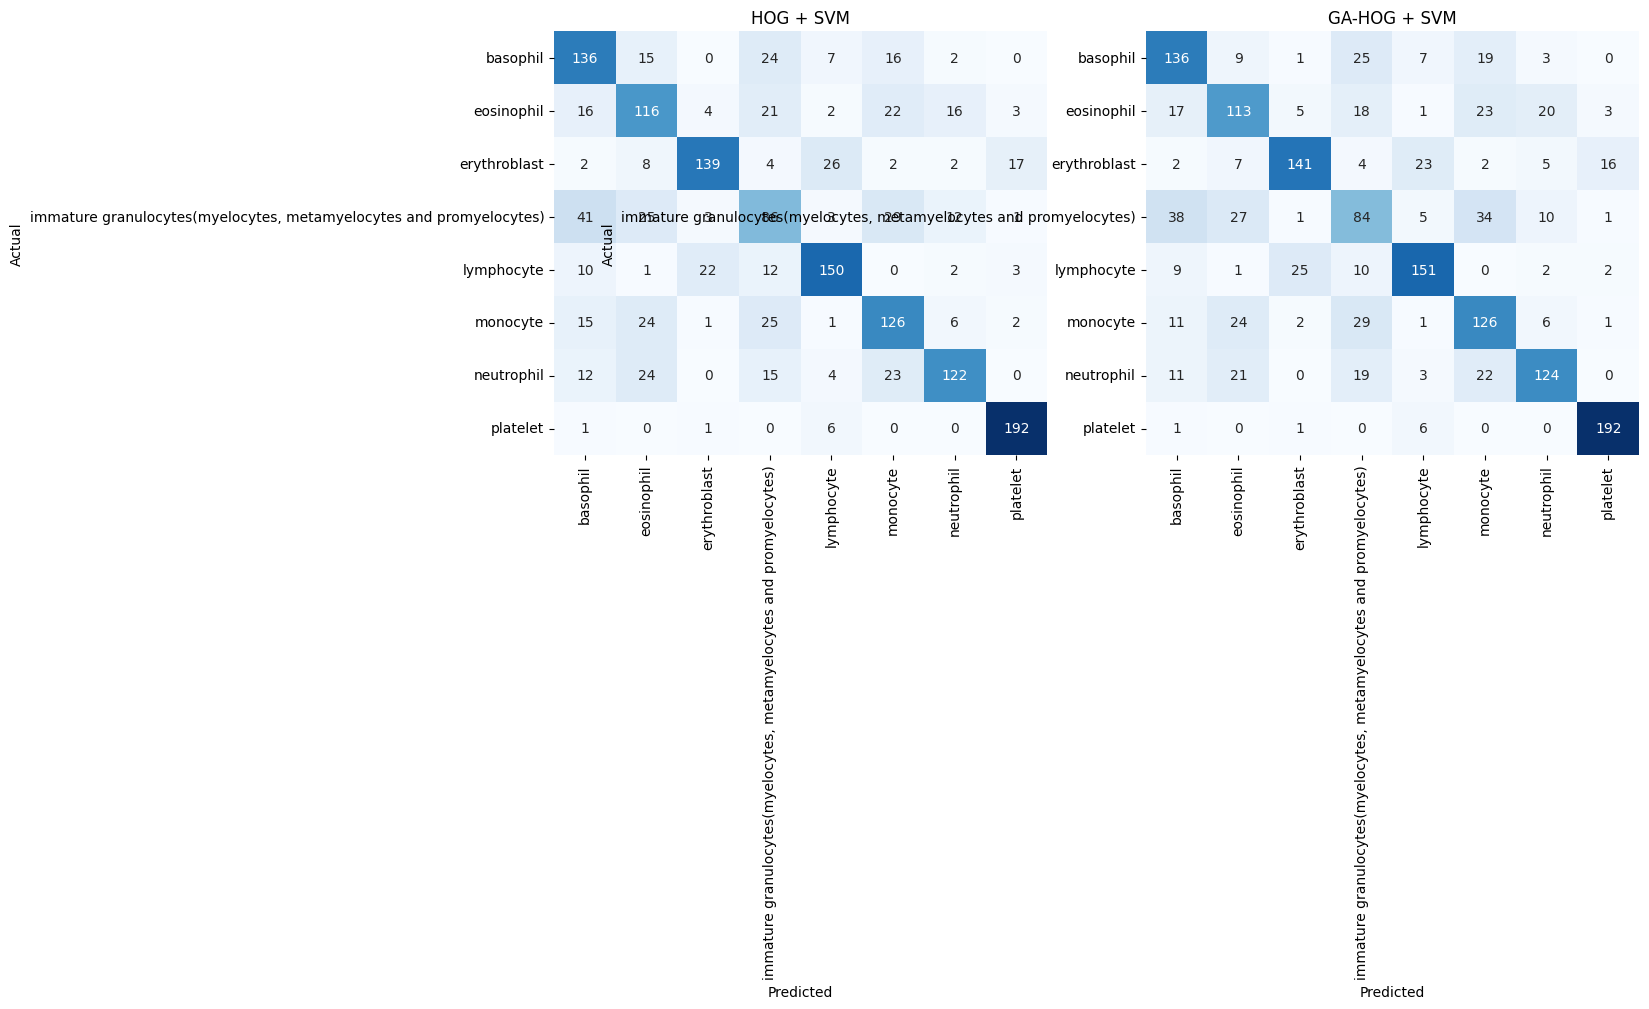

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (title, p) in zip(axes, (("HOG + SVM", pred_base), ("GA-HOG + SVM", pred_ga))):
    sns.heatmap(confusion_matrix(yte, p, labels=range(NUM_CLASSES)), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [22]:
d_f1 = m_ga["Macro-F1 (%)"] - m_base["Macro-F1 (%)"]
d_acc = m_ga["Accuracy (%)"] - m_base["Accuracy (%)"]
reduction = 100 * (1 - len(sel_cols) / D)
print("Research question: did GA feature selection help?")
print("Features: %d -> %d (%.1f%% fewer)" % (D, len(sel_cols), reduction))
print("Accuracy change: %+.2f points | Macro-F1 change: %+.2f points" % (d_acc, d_f1))
if d_f1 > 0:
    print("Result: the GA model scored higher macro-F1 than the baseline while using fewer features.")
elif d_f1 > -1:
    print("Result: about the same performance with far fewer features (macro-F1 within 1 point).")
else:
    print("Result: the GA model lost performance compared with the baseline on this test set.")
print("Extra cost: GA search took %.0f s." % ga_search_time)

Research question: did GA feature selection help?
Features: 8100 -> 4075 (49.7% fewer)
Accuracy change: +0.00 points | Macro-F1 change: -0.02 points
Result: about the same performance with far fewer features (macro-F1 within 1 point).
Extra cost: GA search took 238 s.
